# EDA dữ liệu cảm xúc VLSP — khảo sát trước tiền xử lý

Dữ liệu Base/Augmented được phân tích ở dạng gốc. Test chỉ dùng kiểm toán schema và giao tập, không dùng nhãn test để chọn quy tắc. Mọi tỷ lệ theo nhãn dưới đây chỉ dùng tập phát triển.

In [ ]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub>=0.3,<2', 'transformers<5', 'sentencepiece'])

0

In [ ]:
import re, unicodedata, json, hashlib
from pathlib import Path
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
LABELS = [-1, 0, 1]
DATA_DIR = None
DATASET_HANDLE = 'anhphmduy/vlsp-sentiment-dataset/versions/5'
OUT = Path('vlsp_raw_eda'); OUT.mkdir(exist_ok=True)

In [ ]:
FILES = {
    "Base": ("vlsp_sentiment_train.csv",),
    "Augmented": ("vlsp_sentiment_train_augmented_v2.csv", "augmented_v2.csv"),
    "Test": ("vlsp_sentiment_test.csv",),
}

def locate_inputs(root):
    return {
        name: next((root / filename for filename in filenames if (root / filename).is_file()), None)
        for name, filenames in FILES.items()
    }

def resolve_inputs():
    if DATA_DIR is not None:
        root = Path(DATA_DIR).resolve()
    else:
        candidates = [
            Path("data"), Path("."),
            Path("/kaggle/input/vlsp-sentiment-dataset"),
            Path("/kaggle/input/datasets/anhphmduy/vlsp-sentiment-dataset"),
        ]
        root = next((p for p in candidates if all(locate_inputs(p).values())), None)
        if root is None:
            import kagglehub
            root = Path(kagglehub.dataset_download(DATASET_HANDLE))
            root = next(
                (p.parent for p in sorted(root.rglob(FILES["Base"][0]))
                 if all(locate_inputs(p.parent).values())),
                root,
            )
        root = root.resolve()
    paths = locate_inputs(root)
    missing = ["/".join(FILES[name]) for name, path in paths.items() if path is None]
    if missing:
        raise FileNotFoundError(f"Thiếu dữ liệu VLSP tại {root}: {', '.join(missing)}")
    return root, paths

def read_vlsp(path, split):
    for delimiter in ("\t", ","):
        header = pd.read_csv(path, sep=delimiter, encoding="utf-8-sig", nrows=0)
        if {"Class", "Data"}.issubset(header.columns.str.strip()):
            break
    else:
        raise ValueError(f"{path.name} cần hai cột Class và Data, phân tách bằng tab hoặc dấu phẩy.")
    frame = pd.read_csv(path, sep=delimiter, encoding="utf-8-sig", keep_default_na=False, dtype=str)
    frame.columns = frame.columns.str.strip()
    frame = frame[["Class", "Data"]].copy()
    labels = pd.to_numeric(frame["Class"], errors="coerce")
    invalid = ~labels.isin(LABELS)
    if frame.empty or invalid.any():
        raise ValueError(f"{path.name}: {int(invalid.sum())} nhãn sai hoặc tập rỗng.")
    frame["label"] = labels.astype(int)
    frame = frame.rename(columns={"Data": "text"})
    frame["row"] = np.arange(len(frame))
    frame["sample_id"] = split.lower() + "-" + frame["row"].astype(str)
    return frame[["sample_id", "row", "label", "text"]]

data_root, paths = resolve_inputs()
raw = {name: read_vlsp(path, name) for name, path in paths.items()}
print({name: len(frame) for name, frame in raw.items()})

  0%|          | 0.00/620M [00:00<?, ?B/s]

  3%|▎         | 17.0M/620M [00:00<00:03, 176MB/s]

  6%|▌         | 36.0M/620M [00:00<00:03, 184MB/s]

  9%|▊         | 54.0M/620M [00:00<00:03, 185MB/s]

 12%|█▏        | 72.0M/620M [00:00<00:04, 120MB/s]

 15%|█▍        | 90.0M/620M [00:00<00:04, 137MB/s]

... (29 outputs left out)

 98%|█████████▊| 606M/620M [00:07<00:00, 153MB/s]

100%|██████████| 620M/620M [00:07<00:00, 82.4MB/s]

Extracting files...


{'Base': 5100, 'Augmented': 10149, 'Test': 1050}


## Phân bố, độ dài và chất lượng dữ liệu gốc

Tỷ lệ theo lớp dùng Base và Augmented. Giao test chỉ dựa trên văn bản, không dùng nhãn test.

label,-1,0,1
dataset,,,
Augmented,3385,3387,3377
Base,1700,1700,1700


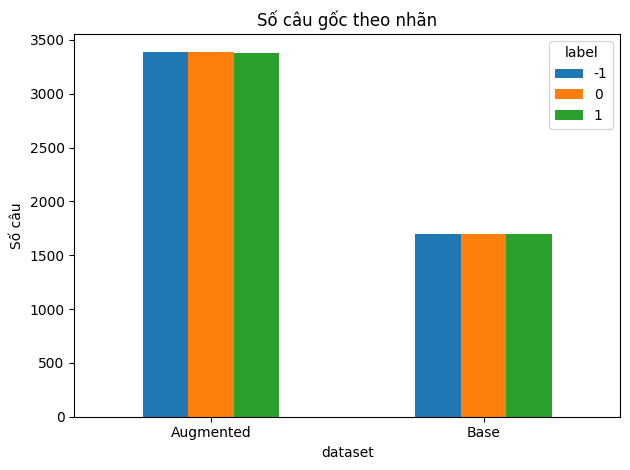

chars   words
dataset   label                      
Augmented -1    0.50     79.0    18.0
                0.90    240.0    54.0
                0.95    346.2    76.0
                0.99    596.6   136.0
                1.00   1656.0   376.0
           0    0.50    105.0    24.0
                0.90    311.4    69.0
                0.95    421.7    95.0
                0.99    907.3   205.0
                1.00  13036.0  2923.0
           1    0.50     71.0    16.0
                0.90    222.0    49.0
                0.95    309.0    69.0
                0.99    605.0   141.0
                1.00   2970.0   667.0
Base      -1    0.50     77.0    17.0
                0.90    230.0    52.0
                0.95    340.1    75.0
                0.99    558.1   133.0
                1.00   1532.0   356.0
           0    0.50    102.0    24.0
                0.90    306.1    68.0
                0.95    416.1    92.0
                0.99    957.2   220.0
                1.00  13164.0  2885.0
           1    0.50     69.0    16.0
                0.90    218.2    48.0
                0.95    298.0    67.0
                0.99    594.1   135.0
                1.00   2753.0   631.0

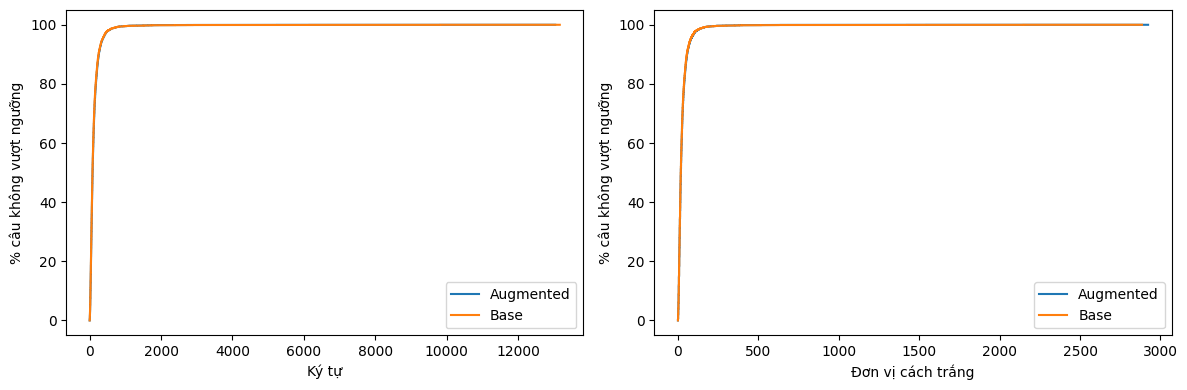

In [ ]:
dev = pd.concat([raw['Base'].assign(dataset='Base'), raw['Augmented'].assign(dataset='Augmented')], ignore_index=True)
counts = dev.groupby(['dataset','label']).size().unstack(fill_value=0).reindex(columns=LABELS,fill_value=0)
display(counts)
counts.to_csv(OUT/'label_counts.csv')
counts.plot.bar(rot=0, title='Số câu gốc theo nhãn', ylabel='Số câu'); plt.tight_layout(); plt.savefig(OUT/'labels.png'); plt.show()
lengths = dev.assign(chars=dev.text.str.len(), words=dev.text.str.split().str.len())
display(lengths.groupby(['dataset','label'])[['chars','words']].quantile([.5,.9,.95,.99,1]).round(1))
fig, axes=plt.subplots(1,2,figsize=(12,4))
for name, part in lengths.groupby('dataset'):
 for ax,col in zip(axes,['chars','words']):
  v=np.sort(part[col]); ax.step(v,100*np.arange(1,len(v)+1)/len(v),label=name)
for ax,col in zip(axes,['Ký tự','Đơn vị cách trắng']): ax.set(xlabel=col,ylabel='% câu không vượt ngưỡng'); ax.legend()
fig.tight_layout(); fig.savefig(OUT/'lengths.png'); plt.show()

,dataset,rows,blank,duplicate_extras,conflicting_keys,overlap_test
0,Base,5100,0,48,0.0,23.0
1,Augmented,10149,0,161,1.0,33.0
2,Test,1050,0,0,NaN,NaN


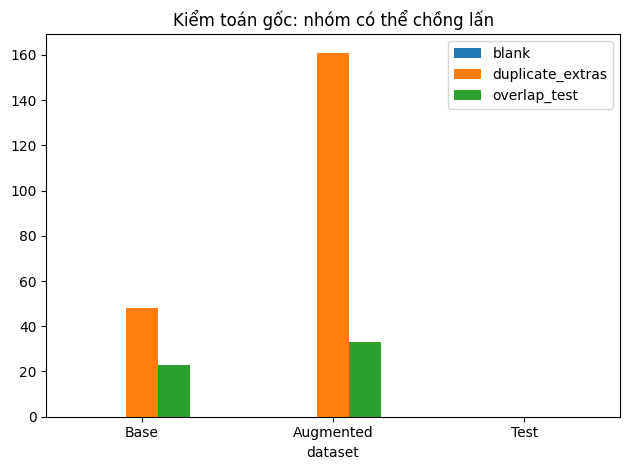

In [ ]:
def raw_key(text): return ' '.join(unicodedata.normalize('NFC',text).casefold().split())
keys={name:frame.text.map(raw_key) for name,frame in raw.items()}
audit=[]
for name,frame in raw.items():
 key=keys[name]; nonblank=key.ne('')
 conflicts=pd.DataFrame({'key':key,'label':frame.label}).loc[nonblank].groupby('key').label.nunique().gt(1).sum() if name!='Test' else None
 audit.append(dict(dataset=name,rows=len(frame),blank=int((~nonblank).sum()),duplicate_extras=int(key[nonblank].duplicated().sum()),conflicting_keys=conflicts,overlap_test=int((nonblank & key.isin(keys['Test'])).sum()) if name!='Test' else None))
audit=pd.DataFrame(audit); display(audit); audit.to_csv(OUT/'raw_audit.csv',index=False)
audit.set_index('dataset')[['blank','duplicate_extras','overlap_test']].plot.bar(rot=0,title='Kiểm toán gốc: nhóm có thể chồng lấn'); plt.tight_layout(); plt.savefig(OUT/'audit.png'); plt.show()

## Tín hiệu trong văn bản gốc

Tỷ lệ là phần trăm câu có ít nhất một tín hiệu; đồng xuất hiện không chứng minh ý nghĩa hay quan hệ nhân quả. Ví dụ lấy theo sample_id để có thể kiểm tra ngữ cảnh.


 phủ định — ví dụ gốc


/tmp/ipykernel_2789/2091302427.py:4: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask=dev.text.str.contains(pat,regex=True,na=False)


,dataset,sample_id,label,text
5101,Augmented,augmented-1,0,"ram lên nhiều làm gì, màn hình độ phân giải th..."
5110,Augmented,augmented-10,-1,"Cấu hình chỉ có ram 1gb 2gb, ssd 16gb, không h..."
15101,Augmented,augmented-10001,0,"có tiền thứ cứ làm cái 65 mà coi cho đã, hỏi l..."
15104,Augmented,augmented-10004,0,"mới đi xem thử sh01f với 304sh về, cam của sh0..."
15105,Augmented,augmented-10005,0,Mình chỉ sạc mỗi tháng một lần nên việc bật tắ...
15107,Augmented,augmented-10007,-1,có 1 triệu tôi cũng không made in china.
15108,Augmented,augmented-10008,0,bạn sai rồi nhé. tôi đã từng xài ip 3 đời..lúc...
15110,Augmented,augmented-10010,0,làm sao để mua được khi tôi ở đà nẵng đây. mà ...


/tmp/ipykernel_2789/2091302427.py:4: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask=dev.text.str.contains(pat,regex=True,na=False)



 teencode ứng viên — ví dụ gốc


,dataset,sample_id,label,text
7803,Augmented,augmented-2703,0,có rất nhiều lựa chọn. mặc dù tôi rất rất iu ip
5522,Augmented,augmented-422,1,"nhìn em iphone iu gì đâu á, mấy em còn lại khô..."
12002,Augmented,augmented-6902,1,"pin máy được nhà sx rất kỳ vọng , là ưu điểm m..."
13356,Augmented,augmented-8256,1,quá tuyệt vời.... điều mà tôi mong mỏi... tôi ...
15045,Augmented,augmented-9945,1,có nhìu bạn lả fan giống mình iu surface quá cơ!
10,Base,base-10,-1,"Mình cũng giật kinh khủng, cảm thấy hơi nản về..."
1001,Base,base-1001,-1,Bác nào đã lấy con A6 bên TCS mà ngoại tỉnh ko...
1002,Base,base-1002,-1,"Cái cảm biến chuyển đôngj kém ghê, quay tay lú..."


... (4 outputs left out)

,dataset,sample_id,label,text
1023,Base,base-1023,-1,Sau khi đọc hết 21 trang comment của mọi người...
1069,Base,base-1069,-1,ôi cái giá tiếp tục ngủ thôi :(
1078,Base,base-1078,-1,đẹp nhưng quá mắc. $1000 thì mua dc chứ giá kh...
1094,Base,base-1094,-1,"Độ nhạy tối đa 6400iso, 3 hình/giây. Công nghệ..."
110,Base,base-110,-1,Xấu hơn S6 active. nhưng nếu về VN mình chọn S...
1113,Base,base-1113,-1,"Giá khá mắc , tuy nhiên nếu bạn nào điều kiện ..."
1136,Base,base-1136,-1,"đeo thiết bị này cẩn thận nhé, vì rất dễ bị dị..."
1141,Base,base-1141,-1,Ai muốn mua cây bút chì chỉ với 99$? :))



 emoji — ví dụ gốc


,dataset,sample_id,label,text


,signal,dataset,label,count,total,percent
0,phủ định,Augmented,-1,1536,3385,45.376662
1,phủ định,Augmented,0,1608,3387,47.475642
2,phủ định,Augmented,1,994,3377,29.434409
3,phủ định,Base,-1,685,1700,40.294118
4,phủ định,Base,0,717,1700,42.176471
5,phủ định,Base,1,454,1700,26.705882
6,teencode ứng viên,Augmented,-1,0,3385,0.000000
7,teencode ứng viên,Augmented,0,1,3387,0.029525
8,teencode ứng viên,Augmented,1,4,3377,0.118448
9,teencode ứng viên,Base,-1,295,1700,17.352941


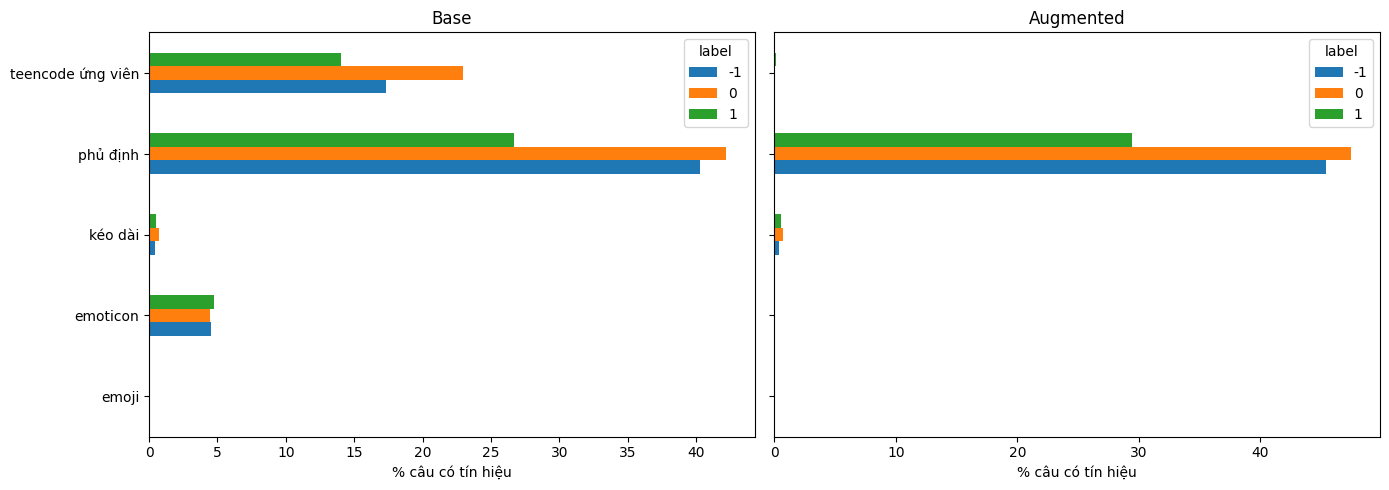

In [ ]:
patterns={'phủ định':r'(?i)(?<!\w)(không|chẳng|chưa|ko|hok|khg)(?!\w)', 'teencode ứng viên':r'(?i)(?<!\w)(ko|hok|khg|đc|dc|sp|đt|thik|iu|mik|vs|bthg|cx)(?!\w)', 'kéo dài':r'(?i)([^\W\d_])\1{2,}', 'emoticon':r'(?i)(?::[-]?[)(d]|\^\^|t\.t)', 'emoji':r'[\U0001F300-\U0001FAFF\u2764\uFE0F]'}
rows=[]
for name,pat in patterns.items():
 mask=dev.text.str.contains(pat,regex=True,na=False)
 for (dataset,label), group in dev.groupby(['dataset','label']):
  subset=mask.loc[group.index]; rows.append({'signal':name,'dataset':dataset,'label':label,'count':int(subset.sum()),'total':len(group),'percent':100*subset.mean()})
 print('\n',name,'— ví dụ gốc'); display(dev.loc[mask,['dataset','sample_id','label','text']].sort_values(['dataset','sample_id']).head(8))
signals=pd.DataFrame(rows); display(signals); signals.to_csv(OUT/'signal_rates.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(14,5),sharey=True)
for ax,name in zip(axes,['Base','Augmented']):
 signals[signals.dataset==name].pivot(index='signal',columns='label',values='percent').plot.barh(ax=ax); ax.set(title=name,xlabel='% câu có tín hiệu',ylabel='')
fig.tight_layout(); fig.savefig(OUT/'signals.png'); plt.show()

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
for name,frame in dev.groupby('dataset'):
 vectorizer=CountVectorizer(ngram_range=(1,2),binary=True,token_pattern=r'(?u)\b\w+\b',min_df=3,max_features=20000)
 matrix=vectorizer.fit_transform(frame.text); terms=vectorizer.get_feature_names_out()
 for label in LABELS:
  idx=np.flatnonzero(frame.label.to_numpy()==label); freq=np.asarray(matrix[idx].sum(axis=0)).ravel(); top=np.argsort(-freq,kind='stable')[:15]
  display(pd.DataFrame({'dataset':name,'label':label,'term':terms[top],'document_count':freq[top]}))

,dataset,label,term,document_count
0,Augmented,-1,không,1396
1,Augmented,-1,có,1012
2,Augmented,-1,là,844
3,Augmented,-1,thì,816
4,Augmented,-1,quá,659
5,Augmented,-1,và,659
6,Augmented,-1,này,586
7,Augmented,-1,mình,574
8,Augmented,-1,của,569
9,Augmented,-1,được,564


,dataset,label,term,document_count
0,Augmented,0,có,1485
1,Augmented,0,không,1459
2,Augmented,0,là,1179
3,Augmented,0,thì,1004
4,Augmented,0,bạn,843
5,Augmented,0,và,798
6,Augmented,0,mình,782
7,Augmented,0,được,782
8,Augmented,0,mua,767
9,Augmented,0,của,741


,dataset,label,term,document_count
0,Augmented,1,không,871
1,Augmented,1,có,846
2,Augmented,1,là,845
3,Augmented,1,và,800
4,Augmented,1,đẹp,786
5,Augmented,1,mình,740
6,Augmented,1,quá,726
7,Augmented,1,dùng,640
8,Augmented,1,rất,630
9,Augmented,1,này,571


,dataset,label,term,document_count
0,Base,-1,thì,450
1,Base,-1,có,421
2,Base,-1,là,420
3,Base,-1,không,418
4,Base,-1,mà,328
5,Base,-1,cái,310
6,Base,-1,quá,299
7,Base,-1,này,287
8,Base,-1,mua,271
9,Base,-1,của,248


,dataset,label,term,document_count
0,Base,0,có,628
1,Base,0,là,573
2,Base,0,thì,539
3,Base,0,không,416
4,Base,0,mà,392
5,Base,0,mua,378
6,Base,0,mình,353
7,Base,0,bạn,342
8,Base,0,cũng,327
9,Base,0,của,323


,dataset,label,term,document_count
0,Base,1,là,409
1,Base,1,quá,375
2,Base,1,đẹp,367
3,Base,1,có,355
4,Base,1,mình,315
5,Base,1,thì,296
6,Base,1,và,294
7,Base,1,dùng,288
8,Base,1,này,279
9,Base,1,mà,257


## Quy tắc ứng viên và giới hạn

EDA ghi nhận tần suất và ví dụ, không tự suy ra nghĩa của emoji hoặc từ viết tắt. Ưu tiên chuẩn Unicode NFC và khoảng trắng; giữ dấu, phủ định, ký hiệu và dạng gốc khi chưa đủ bằng chứng để thay thế ngữ nghĩa. Cần kiểm tra các trường hợp va chạm khi thử quy tắc trước khi đưa vào huấn luyện.